In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# **Анализ актуальности проекта**

## **1. Актуальность проблемы среди работников УК**
В настоящее время, в случае возникновения каких-либо проблем с теплоснабжением и прочими проблемами в ЖКХ, жители находят номер телефона нужной УК и уже по телефону узнают нужную информацию. На следующем графике наглядно представлено соотношение способов связи с управляющими компаниями:   

### **Способы обращения в управляющие компании:**

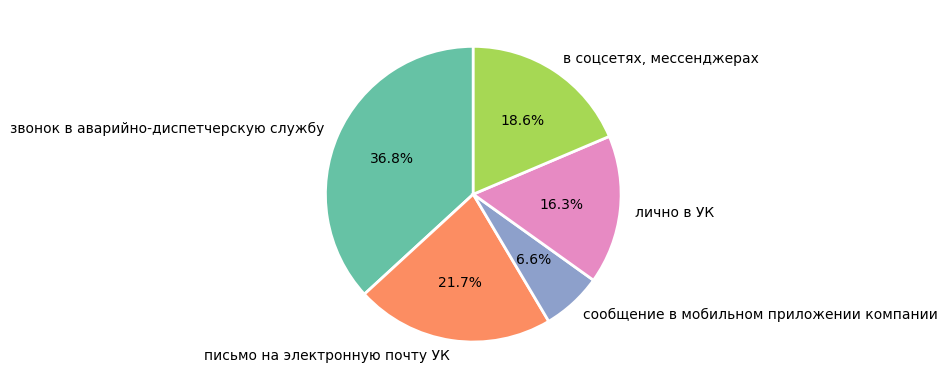

In [ ]:
con = pd.read_csv('Опрос работников УК.csv')

#--------------------
methods = [
    'звонок в аварийно-диспетчерскую службу',
    'письмо на электронную почту УК',
    'сообщение в мобильном приложении компании',
    'лично в УК',
    'в соцсетях, мессенджерах'
]

ways = [len(con[f'По каким каналам поступают заявки от граждан? / {methods[a]}'].dropna()) for a in range(len(methods))]
#---------------------

plt.pie(ways, labels=methods,
        autopct='%1.1f%%',
        startangle=90,
        textprops={"fontsize": 10},
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        colors=plt.cm.Set2.colors)
plt.show()

Как можем видеть на диаграмме, действительно, чаще всего жители обращаются в управляющие компании **по телефону**. На втором же месте у нас **письмо на электронную почту**.  
Что плохого в этих способах? **__Это медленно__**.  

В случае, если в каком-то доме случится поломка, квартиранты станут массово звонить в УК чтобы выяснить причину отсутствия соответствующей коммунальной услуги. В нашем случае: теплоснабжения.

В добавок ко всему, каждую заявку нужно регистрировать, несмотря на массовый характер. А это тоже времязатратно.  

Однако, чтобы полностью оценить сложность в ведении отчетов, нужно знать - каким именно способом это выполняется. _Внимание на следующую диаграмму_:

### **Способы ведения отчета о заявках**

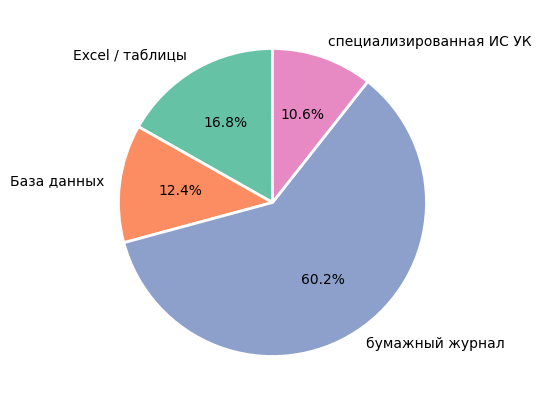

In [ ]:
#----------------
methods = [
    'Excel / таблицы',
    'База данных',
    'бумажный журнал',
    'специализированная ИС УК'
]

tools = [len(con[f'Как Вы регистрируете заявки? / {methods[i]}'].dropna()) for i in range(len(methods))]
#----------------

plt.figure(figsize=(7, 5), dpi=100)
plt.pie(tools, labels=methods,
        autopct='%1.1f%%',
        startangle=90,
        textprops={"fontsize": 10},
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        colors=plt.cm.Set2.colors
        )
plt.show()

Наглядно представлено то, что в более 60% случаев используетсяя **бумажный журнал** для ведения отчетности по заявкам в управляющие компании.  
Диспетчерам приходится **вручную** вносить данные по каждой заявке, хранить множество журналов при себе на случай надобности. А если понадобится найти какую-то кокретную заявку - это может занять кучу времени. Отсюда и формируется статистика неудовлетворенности населением ответами от УК, а то и вовсе - их отсутствием.  

_На следующей диграмме представлены данные по удовлетворености ответом от УК:_

### **Время ответа от управляющих компаний**

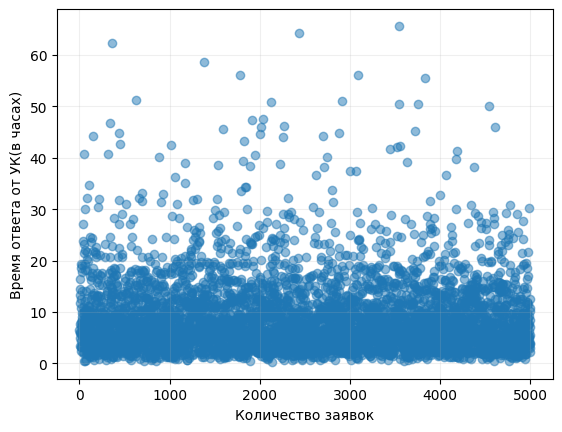

In [58]:
data = pd.read_csv('Заявки жителей.csv')

#----------------------
exctracted_data = data['response_time_hours'].tolist()
x_label = np.arange(0, 5000, 1)
#----------------------

plt.scatter(x_label, exctracted_data, alpha=0.5)
plt.xlabel("Количество заявок")
plt.ylabel("Время ответа от УК(в часах)")
plt.grid(alpha=0.2)
plt.show()

На данном графике можем видеть, что среднее время ответа от управляющих компаний составляет около 9 часов. Всё это время житель находится в ожидании ответа или хоть какой-то информации о том, что случилось.  

И т.к. в большинстве случаев это именно звонки на линию - заявка никак не отслеживается, пользователь остается в невединии долгое время, как показывает график, иногда и **больше суток**.

**Суммируя всё вышеуказанное** - в настоящее время проблема обращения в управляющие компании является достаточно серьёзной. Множество людей слабо или абсолютно не проинформированы о происходящем в ЖКХ, а диспетчеры получают сильную нагрузку, обрабатывая каждую заявку вручную.

**Мой проект** призван помочь диспетчерским быстрее обрабатывать заявки путем интеллекутального анализа и удобного структурирования каждой заявки. Через интерфейс чат-бота диспетчер слегкостью сможет найти нужную заявку, обработать её и дать ответ пользователю.